## PENDAHULUAN 1.2

In [1]:
from neo4j import GraphDatabase, RoutingControl
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "andika2005")
def add_friend(driver, name, friend_name):
   driver.execute_query("MERGE (a:Person {name: $name}) "
                        "MERGE (friend:Person {name: $friend_name}) "
                        "MERGE (a)-[:KNOWS]->(friend)",
                        name=name, friend_name=friend_name, database_="neo4j",)

def print_friends(driver, name):
   records, _, _ = driver.execute_query("MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
                                        "RETURN friend.name ORDER BY friend.name",
                                        name=name, database_="neo4j", routing_=RoutingControl.READ,
                                        )
   for record in records:
     print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
   add_friend(driver, "Arthur", "Guinevere")
   add_friend(driver, "Arthur", "Lancelot")
   add_friend(driver, "Arthur", "Merlin")
   print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

#### 1. Apa nama database yang digunakan pada tutorial ini?

Database yang digunakan adalah neo4j.

#### 2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!

Database lain dalam satu instance Neo4j dapat diakses menggunakan perintah Cypher, seperti `USE` untuk menentukan database yang digunakan dalam query. Selain itu, terdapat perintah untuk melihat dan mengelola database.

Perintah `SHOW DATABASES` digunakan untuk melihat daftar database yang tersedia, sedangkan `USE` digunakan untuk menentukan database yang menjadi konteks query. Perintah `CREATE DATABASE` digunakan untuk membuat database baru apabila didukung oleh versi Neo4j dan hak akses pengguna.

#### 3. Apa jenis graf pertemanan yang telah dibuat di sini?

Graf pertemanan yang dibuat merupakan **graf berarah (*directed graph*)**, karena relationship `KNOWS` memiliki arah dari satu simpul `Person` menuju simpul `Person` lainnya.

## Jawaban Soal UTS

In [6]:
import os
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from sklearn.neighbors import NearestNeighbors
from collections import defaultdict

BOLT = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "andika2005"
SUMBER = "data_train" 

LIMIT = None
BATCH_SIZE = 10000

In [40]:
os.makedirs("gambar", exist_ok=True)

In [2]:
df = pd.read_csv("ecommerce-dataset/events.csv")
df.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## NO.1 Tentukan 2 periode waktu sebagai filter dari data interaksi.

P1 = tanggal 6 Juni 2015 sampai 28 Juni 2015, 
P2 = 29 Juni sampai 7 Juli 2015

In [72]:
def ke_ms(tanggal):
    return int(pd.Timestamp(tanggal, tz="UTC").timestamp() * 1000)

P1_mulai,P1_selesai = ke_ms("2015-06-06 00:00:00"), ke_ms("2015-06-28 23:59:59")
P2_mulai,P2_selesai = ke_ms("2015-06-29 00:00:00"), ke_ms("2015-07-07 23:59:59")

In [74]:
print(P1_mulai,P1_selesai)
print(P2_mulai,P2_selesai)

1433548800000 1435535999000
1435536000000 1436313599000


In [ ]:
train = df[(df["timestamp"] >= P1_mulai) & (df["timestamp"] <= P1_selesai)]
test  = df[(df["timestamp"] >= P2_mulai) & (df["timestamp"] <= P2_selesai)]

In [7]:
train.info

<bound method DataFrame.info of             timestamp  visitorid      event  itemid  transactionid
93661   1433569064254     896988       view   96581            NaN
93662   1433570256041     872999       view  431632            NaN
93663   1433570392312    1076434       view  457407            NaN
93664   1433569461293    1332584       view   64537            NaN
93665   1433569765347     155943       view  105149            NaN
...               ...        ...        ...     ...            ...
566290  1435530717025     700110  addtocart  429846            NaN
566291  1435530975351     286828       view  213123            NaN
566292  1435529309710     103639  addtocart   62652            NaN
566293  1435530485703    1036159       view  325233            NaN
566294  1435526218186     267325       view   67412            NaN

[451826 rows x 5 columns]>

In [8]:
test.info()

<class 'pandas.DataFrame'>
Index: 185974 entries, 548022 to 2201647
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   timestamp      185974 non-null  int64  
 1   visitorid      185974 non-null  int64  
 2   event          185974 non-null  str    
 3   itemid         185974 non-null  int64  
 4   transactionid  1555 non-null    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 8.5 MB


## No.2 Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [15]:
os.makedirs(SUMBER, exist_ok=True)
train.to_csv(f"{SUMBER}/events.csv", index=False)
test.to_csv("ecommerce-dataset/events_test.csv", index=False)
print("Baris training:", len(train), "| Baris testing:", len(test))

Baris training: 451826 | Baris testing: 185974


In [8]:
csv_file_path = os.path.join(SUMBER, "events.csv")
assert os.path.exists(csv_file_path), f"File '{csv_file_path}' tidak ditemukan!"

driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Koneksi ke Neo4j berhasil.")

Koneksi ke Neo4j berhasil.


In [21]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    tx.run("""
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
    """, batch=batch)

    tx.run("""
        UNWIND $batch AS row
        WITH row WHERE row.event = 'view'
        MATCH (v:Visitor {visitorId: row.visitorid}), (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """, batch=batch)

    tx.run("""
        UNWIND $batch AS row
        WITH row WHERE row.event = 'addtocart'
        MATCH (v:Visitor {visitorId: row.visitorid}), (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    """, batch=batch)

    tx.run("""
        UNWIND $batch AS row
        WITH row WHERE row.event = 'transaction'
        MATCH (v:Visitor {visitorId: row.visitorid}), (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i)
    """, batch=batch)

In [ ]:
with open(csv_file_path, encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1
if LIMIT:
    total_rows = min(total_rows, LIMIT)
total_chunks = (total_rows // BATCH_SIZE) + 1

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=BATCH_SIZE, nrows=LIMIT)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = (
            chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        )
        records = chunk[["timestamp", "visitorid", "event",
                         "itemid", "transactionid"]].to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Membaca file data dari: data_train\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 46/46 [03:13<00:00,  4.22s/it]

Proses impor berhasil.


In [22]:
csv_p2 = os.path.join("ecommerce-dataset", "events_test.csv")   # file P2 (30 Jun - 5 Jul)
assert os.path.exists(csv_p2), f"File '{csv_p2}' tidak ditemukan!"

with open(csv_p2, encoding="utf-8") as f:
    total_rows_p2 = sum(1 for _ in f) - 1
total_chunks_p2 = (total_rows_p2 // BATCH_SIZE) + 1

with driver.session() as session:
    chunks = pd.read_csv(csv_p2, chunksize=BATCH_SIZE)
    for chunk in tqdm(chunks, total=total_chunks_p2, desc="Mengimpor P2"):
        chunk["transactionid"] = (
            chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        )
        records = chunk[["timestamp", "visitorid", "event",
                         "itemid", "transactionid"]].to_dict(orient="records")
        session.execute_write(import_batch, records)

print("P2 berhasil ditambahkan ke graf.")

Mengimpor P2: 100%|██████████| 19/19 [01:06<00:00,  3.49s/it]

P2 berhasil ditambahkan ke graf.


## No 3 Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [2]:
P1_MULAI, P1_SELESAI = 1433548800000, 1435535999000
P2_MULAI,  P2_SELESAI = 1435536000000, 1436313599000

In [9]:
INTERAKSI = "VIEWED|ADDED_TO_CART|BOUGHT"

with driver.session() as s:
    per_periode = pd.DataFrame(s.run(f"""
        MATCH (v:Visitor)-[r:{INTERAKSI}]->(i:Item)
        RETURN CASE WHEN r.timestamp <= $p1_selesai THEN 'P1 (training)' ELSE 'P2 (testing)' END AS periode,
               count(DISTINCT v) AS visitor,
               count(DISTINCT i) AS item,
               count(r)          AS total_relasi
        ORDER BY periode
    """, p1_selesai=P1_SELESAI).data())

    total = pd.DataFrame(s.run("""
        MATCH (n)
        RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
    """).data())

    rel_periode = pd.DataFrame(s.run(f"""
        MATCH ()-[r:{INTERAKSI}]->()
        RETURN CASE WHEN r.timestamp <= $p1_selesai THEN 'P1 (training)' ELSE 'P2 (testing)' END AS periode,
               type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY periode, jenis_relasi
    """, p1_selesai=P1_SELESAI).data())


In [79]:
total

,jenis_simpul,jumlah
0,Visitor,327798
1,Item,121080


In [80]:
per_periode

,periode,visitor,item,total_relasi
0,P1 (training),234772,99986,451826
1,P2 (testing),99769,61941,185974


In [81]:
rel_periode

,periode,jenis_relasi,jumlah
0,P1 (training),ADDED_TO_CART,11360
1,P1 (training),BOUGHT,3714
2,P1 (training),VIEWED,436752
3,P2 (testing),ADDED_TO_CART,4561
4,P2 (testing),BOUGHT,1555
5,P2 (testing),VIEWED,179858


 Subgraf yang terbentuk memiliki dua jenis simpul: Visitor (pengunjung) sebanyak **327798** dan Item (produk) sebanyak **121080**. Antarsimpul terhubung oleh tiga jenis relasi: VIEWED, ADDED_TO_CART, dan BOUGHT. Jika dirinci per periode, P1 memuat **234772** visitor, **99986** item, dan **451826** relasi, sedangkan P2 memuat **99769** visitor, **61941** item, dan **185974** relasi

## No.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [10]:
bobot = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}

with driver.session() as s:
    edges = s.run("""
        MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
        WHERE r.timestamp >= $mulai AND r.timestamp <= $selesai
        RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS n
    """, mulai=P1_MULAI, selesai=P1_SELESAI).data()

e = pd.DataFrame(edges)
e["w"] = e["t"].map(bobot) * e["n"]                      
e = e.groupby(["u", "i"], as_index=False)["w"].sum()      

u_idx, u_ids = pd.factorize(e["u"])
i_idx, i_ids = pd.factorize(e["i"])

R = sp.csr_matrix((e["w"], (u_idx, i_idx)), shape=(len(u_ids), len(i_ids)))
print("Matriks R terbentuk dengan shape:", R.shape)

Matriks R terbentuk dengan shape: (234772, 99986)


In [12]:
def karakter(M, nama):
    print(nama)
    print("shape :", M.shape)
    print("dimensi tiap vektor :", f"{M.shape[1]:,}")
    print("jumlah vektor :", f"{M.shape[0]:,}")
    print("elemen tidak nol :", f"{M.nnz:,}")
    print("density : {:.6f}%".format(100 * M.nnz / (M.shape[0] * M.shape[1])))
    print("sparsity : {:.4f}%".format(100 - 100 * M.nnz / (M.shape[0] * M.shape[1])))
    print("rata-rata nonzero/baris :", round(M.nnz / M.shape[0], 2))
    print()

karakter(R, "VSM User (baris = user, dimensi = item)")

item_per_user = np.diff(R.indptr)
print("User yang hanya menyentuh 1 item :", f"{(item_per_user == 1).mean() * 100:.1f}%")
print("User yang menyentuh >= 3 item  :", f"{(item_per_user >= 3).mean() * 100:.1f}%")
print("Median item per user :", int(np.median(item_per_user)))
print("Maksimum item per user :", int(item_per_user.max()))

VSM User (baris = user, dimensi = item)
shape : (234772, 99986)
dimensi tiap vektor : 99,986
jumlah vektor : 234,772
elemen tidak nol : 349,910
density : 0.001491%
sparsity : 99.9985%
rata-rata nonzero/baris : 1.49

User yang hanya menyentuh 1 item : 80.7%
User yang menyentuh >= 3 item  : 7.8%
Median item per user : 1
Maksimum item per user : 841


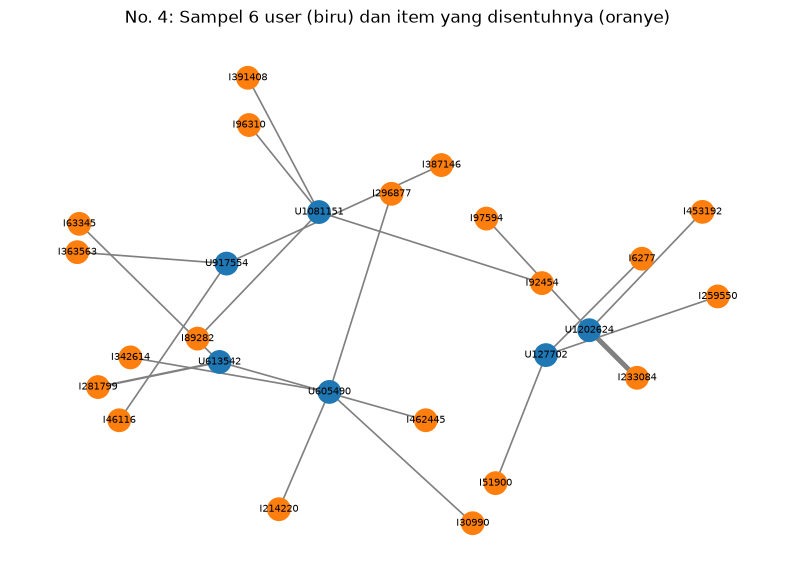

In [13]:
SEED = 42
def gambar_bipartit(G, judul, nama_file):
    warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
    lebar = [0.8 + 0.4 * G[a][b]["weight"] for a, b in G.edges]
    plt.figure(figsize=(10, 7))
    pos = nx.spring_layout(G, seed=SEED, k=0.8)
    nx.draw_networkx(G, pos, node_color=warna, node_size=260, font_size=7, width=lebar, edge_color="gray")
    plt.title(judul)
    plt.axis("off")
    plt.savefig(f"gambar/{nama_file}", dpi=150, bbox_inches="tight")
    plt.show()

rng = np.random.default_rng(SEED)
pool = np.where((item_per_user >= 3) & (item_per_user <= 8))[0]
user_sampel = rng.choice(pool, size=min(6, len(pool)), replace=False)

G_user = nx.Graph()
for uidx in user_sampel:
    baris = R[uidx]
    for j, w in zip(baris.indices, baris.data):
        G_user.add_edge(f"U{u_ids[uidx]}", f"I{i_ids[j]}", weight=float(w))

gambar_bipartit(G_user, "No. 4: Sampel 6 user (biru) dan item yang disentuhnya (oranye)", "no4_vsm_user.png")

## No.5 Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [14]:
Xi_penuh = R.T.tocsr() 
karakter(Xi_penuh, "VSM Item (baris = item, dimensi = user)")

user_per_item = np.diff(R.tocsc().indptr)
print("Item yang hanya disentuh 1 user  :", f"{(user_per_item == 1).mean() * 100:.1f}%")
print("Item yang disentuh >= 3 user     :", f"{(user_per_item >= 3).mean() * 100:.1f}%")
print("Median user per item             :", int(np.median(user_per_item)))
print("Maksimum user per item           :", int(user_per_item.max()))

VSM Item (baris = item, dimensi = user)
shape : (99986, 234772)
dimensi tiap vektor : 234,772
jumlah vektor : 99,986
elemen tidak nol : 349,910
density : 0.001491%
sparsity : 99.9985%
rata-rata nonzero/baris : 3.5

Item yang hanya disentuh 1 user  : 51.2%
Item yang disentuh >= 3 user     : 31.4%
Median user per item             : 1
Maksimum user per item           : 1005


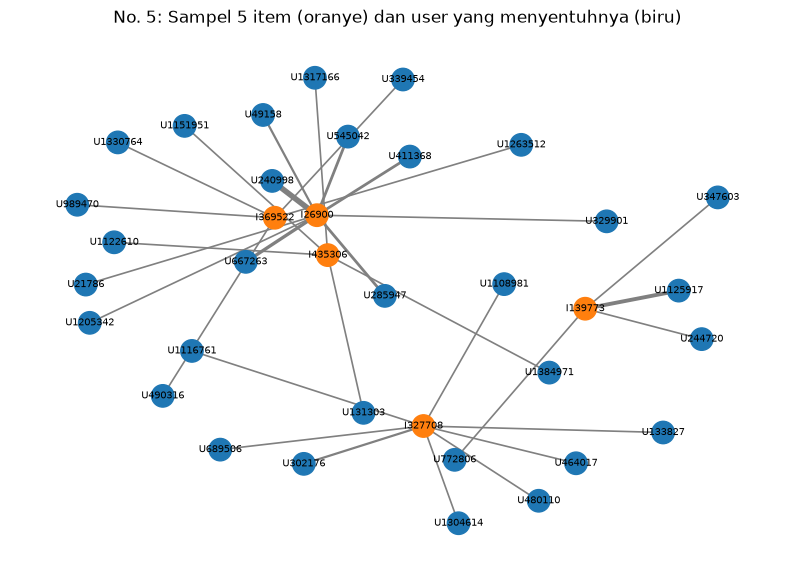

In [88]:
rng = np.random.default_rng(SEED)
pool_i = np.where((user_per_item >= 4) & (user_per_item <= 10))[0]
item_sampel = rng.choice(pool_i, size=min(5, len(pool_i)), replace=False)

R_csc = R.tocsc()
G_item = nx.Graph()
for iidx in item_sampel:
    kolom = R_csc[:, iidx]
    for uidx, w in zip(kolom.indices, kolom.data):
        G_item.add_edge(f"U{u_ids[uidx]}", f"I{i_ids[iidx]}", weight=float(w))

gambar_bipartit(G_item, "No. 5: Sampel 5 item (oranye) dan user yang menyentuhnya (biru)", "no5_vsm_item.png")

## No.6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [15]:
n_user, n_item = R.shape

banding = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah simpul": [n_user, n_item],
    "Ukuran matriks similarity (n x n)": [n_user ** 2, n_item ** 2],
    "% simpul informatif": [
        round((item_per_user >= 2).mean() * 100, 1),     
        round((user_per_item >= 3).mean() * 100, 1),     
    ],
    "Rata-rata data per simpul": [
        round(R.nnz / n_user, 2),                        
        round(R.nnz / n_item, 2),                        
    ],
})
print(banding.to_string(index=False))

rasio = n_user ** 2 / n_item ** 2
lebih_kecil = "Item-Item" if n_item < n_user else "User-User"
print(f"\nMatriks similarity User-User berukuran {rasio:,.1f} kali matriks Item-Item.")
print(f"Proyeksi yang lebih ringan dihitung: {lebih_kecil}.")

 Proyeksi  Jumlah simpul  Ukuran matriks similarity (n x n)  % simpul informatif  Rata-rata data per simpul
User-User         234772                        55117891984                 19.3                       1.49
Item-Item          99986                         9997200196                 31.4                       3.50

Matriks similarity User-User berukuran 5.5 kali matriks Item-Item.
Proyeksi yang lebih ringan dihitung: Item-Item.


### Analisis Pemilihan Proyeksi Graf

Berdasarkan hasil eksplorasi VSM User dan VSM Item, proyeksi Item-Item dipilih karena memiliki jumlah simpul yang lebih sedikit, yaitu 99.986 item, dibandingkan User-User yang memiliki 234.772 user. Selain itu, rata-rata data nonzero pada setiap simpul Item sebesar 3,50, lebih tinggi dibandingkan User sebesar 1,49. Hal ini menunjukkan bahwa setiap item rata-rata memiliki lebih banyak interaksi pengguna untuk digunakan dalam perhitungan kemiripan.

Ukuran matriks similarity Item-Item juga lebih kecil, yaitu sekitar 9,997 miliar elemen, dibandingkan User-User yang mencapai 55,118 miliar elemen. Dengan demikian, proyeksi Item-Item dinilai lebih efisien dari segi ukuran komputasi dan berpotensi lebih efektif untuk menemukan kemiripan antarproduk. Oleh karena itu, proyeksi Item-Item digunakan untuk tahap perhitungan similarity selanjutnya.

## No.7 Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [16]:
with driver.session() as s:
    sebelum = pd.DataFrame(s.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS relasi, count(r) AS jumlah
    """).data())
print("KONDISI SEBELUM similarity:")
sebelum

KONDISI SEBELUM similarity:


,relasi,jumlah
0,VIEWED,616610
1,ADDED_TO_CART,15921
2,BOUGHT,5269
3,SIMILAR_TO,157075


In [18]:
from sklearn.preprocessing import normalize

MIN_USER = 3                  
K = 5                         
MAKS_ITEM_PER_USER = 200      
CHUNK = 500                   

aktif = np.where(user_per_item >= MIN_USER)[0]
id_aktif = i_ids[aktif]
peta_aktif = {int(full): k for k, full in enumerate(aktif)}   
n_aktif = len(aktif)
print(f"Item aktif: {n_aktif:,} dari {n_item:,} item")


Ra = R[:, aktif].tocsr()
n_per_user = np.diff(Ra.indptr)

user_ok = np.where((n_per_user >= 2) & (n_per_user <= MAKS_ITEM_PER_USER))[0]
print(f"User dipakai untuk similarity: {len(user_ok):,} dari {R.shape[0]:,} user")
Ra = Ra[user_ok]

Xi = normalize(Ra.T.tocsr(), norm="l2")        
XiT = Xi.T.tocsr()                             

nb_list = []
for mulai in range(0, n_aktif, CHUNK):
    S = (Xi[mulai:mulai + CHUNK] @ XiT).tocsr()      
    for r in range(S.shape[0]):
        a = mulai + r                                
        awal, akhir = S.indptr[r], S.indptr[r + 1]
        idx = S.indices[awal:akhir]
        val = S.data[awal:akhir]
        mask = idx != a                             
        idx, val = idx[mask], val[mask]
        if len(val) > K:
            top = np.argpartition(-val, K - 1)[:K]  
        else:
            top = np.arange(len(val))
        top = top[np.argsort(-val[top])]            
        nb_list.append([(int(idx[q]), float(min(val[q], 1.0))) for q in top])

    if (mulai // CHUNK) % 10 == 0:
        print(f"  diproses {min(mulai + CHUNK, n_aktif):,} / {n_aktif:,} item")

punya_tetangga = sum(1 for x in nb_list if len(x) > 0)
print(f"Item yang punya tetangga: {punya_tetangga:,} dari {n_aktif:,}")
print("Contoh tetangga item pertama:", [(int(id_aktif[b]), round(sim, 3)) for b, sim in nb_list[0]])

Item aktif: 31,415 dari 99,986 item
User dipakai untuk similarity: 34,521 dari 234,772 user
  diproses 500 / 31,415 item
  diproses 5,500 / 31,415 item
  diproses 10,500 / 31,415 item
  diproses 15,500 / 31,415 item
  diproses 20,500 / 31,415 item
  diproses 25,500 / 31,415 item
  diproses 30,500 / 31,415 item
Item yang punya tetangga: 24,648 dari 31,415
Contoh tetangga item pertama: [(36497, 0.183), (299817, 0.153), (372982, 0.13), (264604, 0.108), (283916, 0.031)]


In [19]:
from sklearn.preprocessing import normalize

MIN_USER = 3        
AMBANG = 0.10       

Xn = normalize(Xi_penuh, norm="l2")               

acuan_idx = int(np.argmax(user_per_item))
acuan = int(i_ids[acuan_idx])
print("Item acuan:", acuan, "| disentuh oleh", int(user_per_item[acuan_idx]), "user")

sim_acuan = (Xn @ Xn[acuan_idx].T).toarray().ravel()
sim_acuan[acuan_idx] = 0                         
sim_acuan[user_per_item < MIN_USER] = 0          

pilih = np.where(sim_acuan >= AMBANG)[0]
print(f"Item dengan similarity >= {AMBANG}: {len(pilih):,} dari {n_item:,} item")

rows = [
    {"a": acuan, "b": int(i_ids[j]), "score": float(min(sim_acuan[j], 1.0))}
    for j in pilih
]

qw = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a})
MATCH (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
"""
with driver.session() as s:
    for k in range(0, len(rows), 50000):
        s.run(qw, rows=rows[k:k + 50000])

print("Relasi SIMILAR_TO yang ditulis:", f"{len(rows):,}")

Item acuan: 5411 | disentuh oleh 1005 user
Item dengan similarity >= 0.1: 5 dari 99,986 item
Relasi SIMILAR_TO yang ditulis: 5


## No.7A Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [20]:
query_top5 = """
MATCH (a:Item {itemId: $acuan})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5
"""
with driver.session() as s:
    top5_df = pd.DataFrame(s.run(query_top5, acuan=acuan).data())
top5_df

,item_mirip,similarity
0,33030,0.202745
1,256242,0.190378
2,89143,0.176341
3,33956,0.144466
4,459936,0.113553


Dengan item acuan 5411 , lima item paling mirip adalah 33030 , 256242 , 89143 , 33956 , dan 459936 , dengan similarity masing-masing 0.202745 sampai 0.113553 . Query Cypher mencari item acuan, mengikuti relasi SIMILAR_TO ke item lain, lalu mengurutkan dari skor tertinggi dan mengambil 5 teratas.

## No.7B Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [21]:
with driver.session() as session:
    result = session.run("""
        MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)
        RETURN a.itemId AS item_acuan,
               b.itemId AS item_mirip,
               r.score AS similarity
        ORDER BY similarity DESC
        LIMIT 5
    """).data()

print(pd.DataFrame(result).to_string(index=False))

 item_acuan  item_mirip  similarity
       5411       33030    0.202745
       5411      256242    0.190378
       5411       89143    0.176341
       5411       33956    0.144466
       5411      459936    0.113553


~~~ cypher
MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)
RETURN  a.itemId AS item_acuan,
        b.itemId AS item_mirip,
        r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
~~~


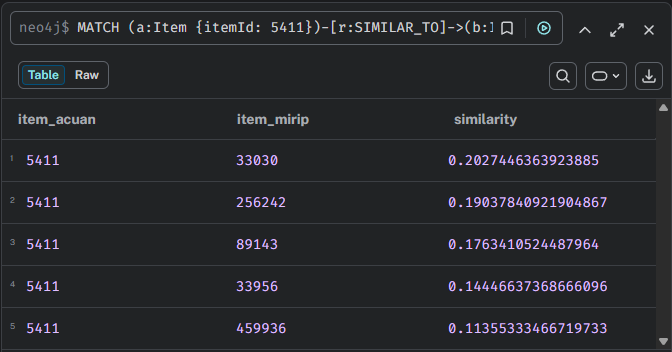

## No.8 Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

**SEBELUM similarity (hanya relasi interaksi)**
~~~ cypher
MATCH p = (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: 5411})
WHERE r.timestamp <= 1435535999000
RETURN p LIMIT 25
~~~

**SESUDAH similarity (muncul relasi SIMILAR_TO)**
~~~ cypher
MATCH p = (a:Item {itemId: 5411})-[:SIMILAR_TO]->(b:Item)
RETURN p
~~~

**Gabungan**
~~~ cypher
MATCH p1 = (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(a:Item {itemId: 5411})
WHERE r.timestamp <= 1435535999000
MATCH p2 = (a)-[:SIMILAR_TO]->(b:Item)
RETURN p1, p2 LIMIT 40
~~~

### Sebelum
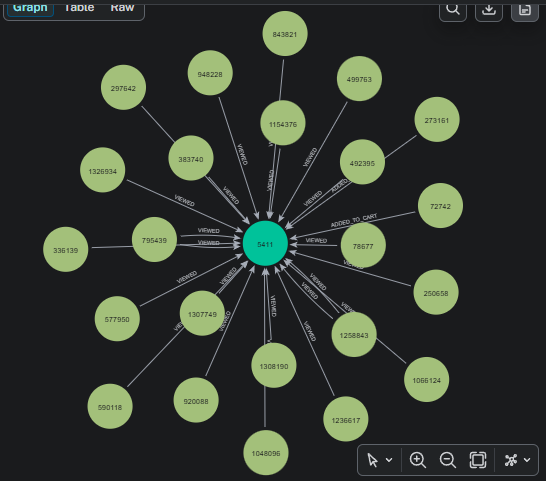

### Sesudah
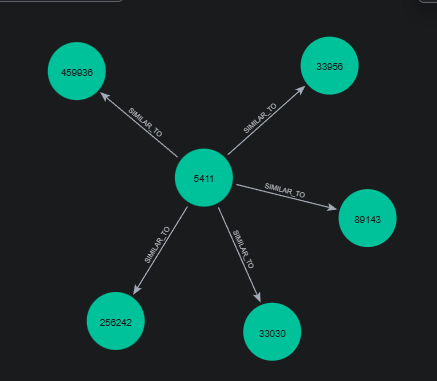


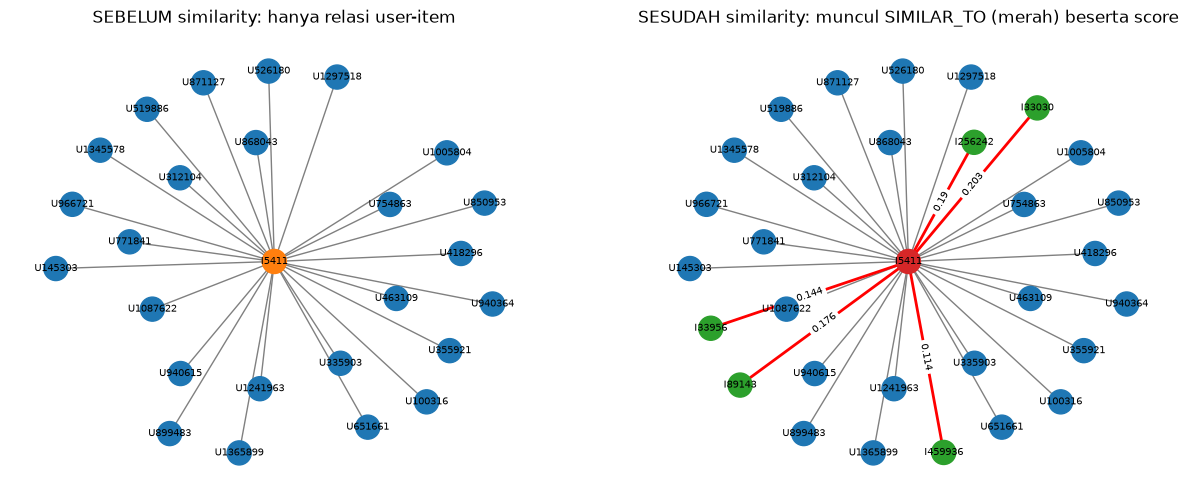

In [22]:
pengunjung = e[e["i"] == acuan]["u"]
pengunjung = pengunjung.sample(min(25, len(pengunjung)), random_state=SEED)

G = nx.Graph()
for u in pengunjung:
    G.add_edge(f"U{u}", f"I{acuan}", jenis="interaksi")
for _, r in top5_df.iterrows():
    G.add_edge(f"I{acuan}", f"I{int(r['item_mirip'])}", jenis="similarity", score=round(float(r["similarity"]), 3))

pos = nx.spring_layout(G, seed=SEED)
G_sebelum = nx.Graph()
G_sebelum.add_edges_from([(a, b, d) for a, b, d in G.edges(data=True) if d["jenis"] == "interaksi"])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

nx.draw_networkx(G_sebelum, {n: pos[n] for n in G_sebelum.nodes}, ax=ax[0], font_size=7, node_size=300,
                 node_color=["tab:orange" if n.startswith("I") else "tab:blue" for n in G_sebelum.nodes],
                 edge_color="gray")
ax[0].set_title("SEBELUM similarity: hanya relasi user-item")
ax[0].axis("off")

warna = []
for n in G.nodes:
    if n == f"I{acuan}":
        warna.append("tab:red")
    elif n.startswith("U"):
        warna.append("tab:blue")
    else:
        warna.append("tab:green")
sisi_sim = [(a, b) for a, b, d in G.edges(data=True) if d["jenis"] == "similarity"]
sisi_int = [(a, b) for a, b, d in G.edges(data=True) if d["jenis"] == "interaksi"]
nx.draw_networkx_nodes(G, pos, ax=ax[1], node_color=warna, node_size=300)
nx.draw_networkx_labels(G, pos, ax=ax[1], font_size=7)
nx.draw_networkx_edges(G, pos, edgelist=sisi_int, ax=ax[1], edge_color="gray")
nx.draw_networkx_edges(G, pos, edgelist=sisi_sim, ax=ax[1], edge_color="red", width=2)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): d["score"] for a, b, d in G.edges(data=True)
                                                  if d["jenis"] == "similarity"}, ax=ax[1], font_size=7)
ax[1].set_title("SESUDAH similarity: muncul SIMILAR_TO (merah) beserta score")
ax[1].axis("off")

plt.savefig("gambar/no8_sebelum_sesudah.png", dpi=150, bbox_inches="tight")
plt.show()

# Bagian 2.2 Analitycs

## No 2.1 Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi)

## 2.1A tuliskan skrip Python dalam merekomendasikan KNN-nya!

Rekomendasi memakai item-based KNN (NearestNeighbors, jarak cosine, k = 5). KNN hanya dihitung untuk item-item yang pernah disentuh user terpilih, bukan untuk seluruh item, sehingga prosesnya ringan. Setiap item milik user mencari 5 tetangga terdekatnya, lalu skor tiap kandidat = bobot interaksi × (1 − jarak cosine) dan dijumlahkan.

In [97]:
MIN_USER = 3
K = 5

aktif = np.where(user_per_item >= MIN_USER)[0]          
id_aktif = i_ids[aktif]
peta_aktif = {int(full): k for k, full in enumerate(aktif)}   
print(f"Item aktif: {len(aktif):,} dari {n_item:,} item")

Xi_knn = Xi_penuh[aktif]                                 

knn = NearestNeighbors(n_neighbors=K + 1, metric="cosine", algorithm="brute").fit(Xi_knn)
print("Model KNN siap.")

Item aktif: 31,415 dari 99,986 item
Model KNN siap.


In [98]:
with driver.session() as s:
    test_rows = s.run("""
        MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
        WHERE r.timestamp >= $mulai AND r.timestamp <= $selesai
        RETURN DISTINCT v.visitorId AS u, i.itemId AS i
    """, mulai=P2_MULAI, selesai=P2_SELESAI).data()

test_graf = pd.DataFrame(test_rows)
print("Pasangan user-item di P2:", f"{len(test_graf):,}")

test_per_user = test_graf.groupby("u")["i"].apply(lambda x: set(int(k) for k in x)).to_dict()
train_per_user = e.groupby("u")["i"].apply(lambda x: set(int(k) for k in x)).to_dict()

def relevan_baru(u):
    """Ground truth: item yang disentuh user di P2 DAN belum pernah disentuh di P1."""
    return test_per_user.get(u, set()) - train_per_user.get(u, set())

R_aktif = R[:, aktif].tocsr()
item_aktif_per_user = np.diff(R_aktif.indptr)

kandidat = sorted(
    int(u_ids[k]) for k in np.where(item_aktif_per_user >= 3)[0]
    if len(relevan_baru(int(u_ids[k]))) > 0
)

rng = np.random.default_rng(SEED)
user_pilihan = int(rng.choice(kandidat))
print("Jumlah kandidat user :", f"{len(kandidat):,}")
print("User terpilih (seed", SEED, "):", user_pilihan)

Pasangan user-item di P2: 146,930
Jumlah kandidat user : 958
User terpilih (seed 42 ): 160428


In [99]:
u_pos = {int(u): k for k, u in enumerate(u_ids)}    

def rekomendasi_knn(user_id, top_n=5, k=5):
    baris = R[u_pos[user_id]]
    sudah = {int(i_ids[j]) for j in baris.indices}  

    pasangan = [(peta_aktif[int(j)], w) for j, w in zip(baris.indices, baris.data)
                if int(j) in peta_aktif]
    if not pasangan:
        return []

    idx_aktif = [a for a, _ in pasangan]
    jarak, tetangga = knn.kneighbors(Xi_knn[idx_aktif], n_neighbors=k + 1)

    skor = defaultdict(float)
    for (a, w), d_baris, n_baris in zip(pasangan, jarak, tetangga):

        for d, b in [(d, b) for d, b in zip(d_baris, n_baris) if b != a][:k]:
            item_id = int(id_aktif[b])
            if item_id not in sudah:               
                skor[item_id] += w * (1 - d)       
    urut = sorted(skor.items(), key=lambda x: x[1], reverse=True)[:top_n]
    return [(i, round(s, 4)) for i, s in urut]

riwayat = e[e["u"] == user_pilihan].sort_values("w", ascending=False)
print("Riwayat user di training (i = itemId, w = bobot interaksi):")
print(riwayat[["i", "w"]].head(10).to_string(index=False))

hasil = rekomendasi_knn(user_pilihan, top_n=5, k=5)
print("\nTop-5 rekomendasi (itemId, skor):")
for rank, (item, skor_) in enumerate(hasil, 1):
    print(f"  {rank}. item {item}  skor {skor_}")


Riwayat user di training (i = itemId, w = bobot interaksi):
     i  w
403645  3
  4613  1
184205  1
196484  1

Top-5 rekomendasi (itemId, skor):
  1. item 12613  skor 1.2649
  2. item 246075  skor 0.9585
  3. item 412793  skor 0.7542
  4. item 349226  skor 0.6276
  5. item 160904  skor 0.5572


## No.2.1B berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [100]:
iklan = [item for item, _ in hasil[:3]]
print("\nTiga item yang diiklankan (k = 5) untuk user", user_pilihan, ":", iklan)


Tiga item yang diiklankan (k = 5) untuk user 160428 : [12613, 246075, 412793]


Dengan k = 5 (tiap item dibandingkan dengan 5 tetangga terdekat), tiga item teratas yang diiklankan kepada user 160428 adalah 12613, 246075, dan 412793. Ketiganya dipilih karena memiliki akumulasi skor tertinggi, yang berarti paling banyak didukung oleh item-item yang pernah disentuh user dan paling mirip dengannya.

## NO 2.2 Berdasarkan hasil rekomendasi Anda no. 1b Analytics hitunglah Hit@5 dan NDCG@5

In [101]:
def hit_ndcg_at_k(rekom, relevan, k=5):
    """Hitung Hit@k dan NDCG@k."""
    top = rekom[:k]
    hit = int(any(i in relevan for i in top))
    dcg = sum(1 / np.log2(pos + 2) for pos, i in enumerate(top) if i in relevan)
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(relevan), k)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return hit, ndcg

relevan = relevan_baru(user_pilihan)
top5 = [item for item, _ in hasil]

rincian = pd.DataFrame({
    "posisi": range(1, len(top5) + 1),
    "itemId": top5,
    "relevan (item baru di P2)": [int(i in relevan) for i in top5],
    "gain 1/log2(posisi+1)": [round(1 / np.log2(p + 1), 4) for p in range(1, len(top5) + 1)],
})
print("Item relevan (baru) di P2:", sorted(relevan))
print(rincian.to_string(index=False))

Item relevan (baru) di P2: [438748]
 posisi  itemId  relevan (item baru di P2)  gain 1/log2(posisi+1)
      1   12613                          0                 1.0000
      2  246075                          0                 0.6309
      3  412793                          0                 0.5000
      4  349226                          0                 0.4307
      5  160904                          0                 0.3869


## 2.2 A Hitung Hit@5

In [102]:
hit5, ndcg5 = hit_ndcg_at_k(top5, relevan, k=5)
print(f"\nHit@5  = {hit5}")


Hit@5  = 0


## 2.2 B Hitung NDCG@5

In [103]:
print(f"NDCG@5 = {ndcg5:.4f}")

NDCG@5 = 0.0000


Berdasarkan hasil evaluasi sistem rekomendasi, diperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,0000. Nilai Hit@5 menunjukkan bahwa tidak terdapat item rekomendasi yang sesuai dengan item relevan pada data pengujian dalam lima rekomendasi teratas. Sementara itu, nilai NDCG@5 sebesar 0,0000 menunjukkan bahwa sistem belum memberikan rekomendasi relevan pada lima posisi teratas berdasarkan kriteria evaluasi yang digunakan.